# SeaTrace — TASSE Surface Current Extraction

This notebook creates a **small, usable ocean-current dataset for the SeaTrace project** from the CSIRO **TASSE v1.5 SHOC hydrodynamic model**.

### What this notebook does
1. Opens one TASSE daily NetCDF file remotely using OPeNDAP.
2. Inspects the model grid and coordinate names.
3. Crops the data to a small Tower Bay / Dover study window.
4. Selects the **near-surface layer** (closest to -0.25 m).
5. Keeps only:
   - `u` = eastward current velocity
   - `v` = northward current velocity
6. Calculates:
   - current speed
   - current direction
7. Creates a current-arrow plot.
8. Exports clean datasets for later SeaTrace particle tracking and GIS work.

> **Important:** The bounding box below is a starter study window around Dover/Tower Bay, not the exact seaweed lease boundary. Replace it with the confirmed lease coordinates when available.

In [1]:
# Run once if these packages are not already installed.
%pip install -q xarray netCDF4 numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and configuration

Change `SOURCE_DATE` if you want another available TASSE daily file.

The URL pattern is:

`https://cem.csiro.au/thredds/dodsC/tasse/hydro/1.5/tasse_simple_YYYY-MM-DD.nc`

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# USER CONFIGURATION
# ---------------------------------------------------------------------

# Daily TASSE file to use.
SOURCE_DATE = "2025-07-15"

# Starter bounding box around the Dover / Tower Bay area.
# Replace these values with the confirmed lease boundary when available.
LAT_MIN = -43.45
LAT_MAX = -43.15
LON_MIN = 146.85
LON_MAX = 147.20

# Target near-surface depth in metres.
# TASSE includes a level close to -0.25 m.
TARGET_DEPTH_M = -0.25

# Variables needed for horizontal current transport.
U_VAR = "u"
V_VAR = "v"

# Output directory.
OUTPUT_DIR = Path("seatrace_tasse_output")
OUTPUT_DIR.mkdir(exist_ok=True)

# Build the remote OPeNDAP URL.
URL = (
    "https://cem.csiro.au/thredds/dodsC/"
    f"tasse/hydro/1.5/tasse_simple_{SOURCE_DATE}.nc"
)

print("Remote dataset:")
print(URL)
print()
print("Output directory:")
print(OUTPUT_DIR.resolve())

Remote dataset:
https://cem.csiro.au/thredds/dodsC/tasse/hydro/1.5/tasse_simple_2025-07-15.nc

Output directory:
/home/n12506486/ifn680/IFN680_26s2/week_7/seatrace_tasse_output


## 2. Open the TASSE dataset remotely

`xarray.open_dataset()` opens the remote NetCDF dataset through OPeNDAP.

This does **not** immediately download the full large file. Data are loaded when they are actually needed.

In [3]:
ds = xr.open_dataset(URL)

print(ds)

<xarray.Dataset> Size: 3GB
Dimensions:    (j: 400, i: 490, time: 24, k: 35)
Coordinates:
    longitude  (j, i) float64 2MB ...
    latitude   (j, i) float64 2MB ...
  * time       (time) datetime64[ns] 192B 2025-07-14T14:00:00 ... 2025-07-15T...
    zc         (k) float64 280B ...
Dimensions without coordinates: j, i, k
Data variables:
    botz       (j, i) float64 2MB ...
    eta        (time, j, i) float32 19MB ...
    u          (time, k, j, i) float32 659MB ...
    v          (time, k, j, i) float32 659MB ...
    salt       (time, k, j, i) float32 659MB ...
    temp       (time, k, j, i) float32 659MB ...
    wspeed_u   (time, j, i) float32 19MB ...
    wspeed_v   (time, j, i) float32 19MB ...
Attributes:
    title:                           TASSE
    description:                     TASSE
    paramhead:                       TASSE : SETAS run1 forced
    paramfile:                       prm/tasse_nrt.prm
    ems_version:                     v1.4.0 rev(7024)
    date_created:      

## 3. Inspect dimensions, coordinates and variables

TASSE uses a **curvilinear grid**, so the horizontal dimensions are typically `j` and `i`, not `lat` and `lon`.

Latitude and longitude are normally 2-D arrays defined over `(j, i)`. This is why code such as:

```python
ds.sel(lat=slice(...), lon=slice(...))
```

fails for this dataset.

In [4]:
print("Dimensions:")
print(ds.dims)

print("\nCoordinates:")
print(list(ds.coords))

print("\nData variables:")
print(list(ds.data_vars))

print("\nAvailable times:")
print(ds["time"].values)

Dimensions:
FrozenMappingWarningOnValuesAccess({'j': 400, 'i': 490, 'time': 24, 'k': 35})

Coordinates:
['zc', 'longitude', 'latitude', 'time']

Data variables:
['botz', 'eta', 'u', 'v', 'salt', 'temp', 'wspeed_u', 'wspeed_v']

Available times:
['2025-07-14T14:00:00.000000000' '2025-07-14T15:00:00.000000000'
 '2025-07-14T15:59:59.999999872' '2025-07-14T17:00:00.000000000'
 '2025-07-14T18:00:00.000000000' '2025-07-14T18:59:59.999999872'
 '2025-07-14T20:00:00.000000000' '2025-07-14T21:00:00.000000000'
 '2025-07-14T21:59:59.999999872' '2025-07-14T23:00:00.000000000'
 '2025-07-15T00:00:00.000000000' '2025-07-15T00:59:59.999999872'
 '2025-07-15T02:00:00.000000000' '2025-07-15T03:00:00.000000000'
 '2025-07-15T03:59:59.999999872' '2025-07-15T05:00:00.000000000'
 '2025-07-15T06:00:00.000000000' '2025-07-15T06:59:59.999999872'
 '2025-07-15T08:00:00.000000000' '2025-07-15T09:00:00.000000000'
 '2025-07-15T09:59:59.999999872' '2025-07-15T11:00:00.000000000'
 '2025-07-15T12:00:00.000000000' '2025-0

## 4. Detect latitude and longitude variable names

This cell checks common coordinate names automatically.

In [5]:
def find_first_existing(dataset, candidates):
    """Return the first variable/coordinate name found in the dataset."""
    for name in candidates:
        if name in dataset.variables:
            return name
    raise KeyError(
        f"None of these names were found: {candidates}. "
        f"Available variables are: {list(dataset.variables)}"
    )

LAT_NAME = find_first_existing(ds, ["latitude", "lat", "nav_lat"])
LON_NAME = find_first_existing(ds, ["longitude", "lon", "nav_lon"])

print("Latitude variable :", LAT_NAME)
print("Longitude variable:", LON_NAME)
print("Latitude dimensions :", ds[LAT_NAME].dims)
print("Longitude dimensions:", ds[LON_NAME].dims)

Latitude variable : latitude
Longitude variable: longitude
Latitude dimensions : ('j', 'i')
Longitude dimensions: ('j', 'i')


## 5. Locate the Tower Bay/Dover study window on the curvilinear grid

Because latitude and longitude are 2-D arrays, we:

1. build a geographic mask;
2. identify the matching `j` and `i` grid cells;
3. find the smallest rectangular grid window containing them.

Only the small `j/i` region is used for the current data.

In [6]:
lat = ds[LAT_NAME]
lon = ds[LON_NAME]

geo_mask = (
    (lat >= LAT_MIN) &
    (lat <= LAT_MAX) &
    (lon >= LON_MIN) &
    (lon <= LON_MAX)
)

# Convert the geographic mask into j/i indices.
jj, ii = np.where(np.asarray(geo_mask))

if len(jj) == 0:
    raise ValueError(
        "No TASSE grid cells were found inside the requested bounding box. "
        "Check LAT_MIN/LAT_MAX/LON_MIN/LON_MAX."
    )

j_min, j_max = int(jj.min()), int(jj.max())
i_min, i_max = int(ii.min()), int(ii.max())

print(f"Matched grid cells: {len(jj):,}")
print(f"j range: {j_min} to {j_max}")
print(f"i range: {i_min} to {i_max}")

Matched grid cells: 12,959
j range: 105 to 298
i range: 43 to 222


## 6. Crop the remote dataset before loading current data

This reduces the spatial area from the full TASSE domain to only the local study window.

In [7]:
local = ds.isel(
    j=slice(j_min, j_max + 1),
    i=slice(i_min, i_max + 1)
)

print(local)

<xarray.Dataset> Size: 480MB
Dimensions:    (j: 194, i: 180, time: 24, k: 35)
Coordinates:
    longitude  (j, i) float64 279kB 146.8 146.8 146.8 146.9 ... nan nan nan nan
    latitude   (j, i) float64 279kB -43.49 -43.49 -43.49 -43.49 ... nan nan nan
  * time       (time) datetime64[ns] 192B 2025-07-14T14:00:00 ... 2025-07-15T...
    zc         (k) float64 280B ...
Dimensions without coordinates: j, i, k
Data variables:
    botz       (j, i) float64 279kB ...
    eta        (time, j, i) float32 3MB ...
    u          (time, k, j, i) float32 117MB ...
    v          (time, k, j, i) float32 117MB ...
    salt       (time, k, j, i) float32 117MB ...
    temp       (time, k, j, i) float32 117MB ...
    wspeed_u   (time, j, i) float32 3MB ...
    wspeed_v   (time, j, i) float32 3MB ...
Attributes:
    title:                           TASSE
    description:                     TASSE
    paramhead:                       TASSE : SETAS run1 forced
    paramfile:                       prm/tasse_

## 7. Select the near-surface TASSE layer

The model has a vertical dimension `k` and normally provides vertical-level values in `zc`.

Instead of assuming that `k=0` is the surface, this notebook finds the level **closest to -0.25 m**.

In [8]:
if "zc" not in ds.variables:
    raise KeyError(
        "The expected vertical coordinate 'zc' was not found. "
        "Inspect the dataset output above for the vertical-level variable."
    )

zc_values = np.asarray(ds["zc"].values)

surface_k = int(np.nanargmin(np.abs(zc_values - TARGET_DEPTH_M)))
actual_depth = float(zc_values[surface_k])

print("Available vertical levels (m):")
print(zc_values)

print(f"\nSelected k index: {surface_k}")
print(f"Selected depth  : {actual_depth:.2f} m")

Available vertical levels (m):
[-170.   -150.   -130.   -112.5   -97.5   -83.5   -71.    -60.    -51.
  -43.5   -37.    -31.5   -27.    -23.25  -20.    -17.25  -14.85  -12.7
  -10.95   -9.6    -8.5    -7.55   -6.7    -5.95   -5.3    -4.75   -4.25
   -3.75   -3.25   -2.75   -2.25   -1.75   -1.25   -0.75   -0.25]

Selected k index: 34
Selected depth  : -0.25 m


## 8. Extract only surface `u` and `v`

`u` and `v` are the horizontal water-velocity components:

- `u > 0` → eastward flow
- `u < 0` → westward flow
- `v > 0` → northward flow
- `v < 0` → southward flow

These are the key inputs for later SeaTrace particle tracking.

In [9]:
for required_var in [U_VAR, V_VAR]:
    if required_var not in local.data_vars:
        raise KeyError(
            f"Required current variable '{required_var}' is missing. "
            f"Available variables: {list(local.data_vars)}"
        )

surface = local[[U_VAR, V_VAR]].isel(k=surface_k)

# Re-create an exact geographic mask on the cropped grid.
local_lat = local[LAT_NAME]
local_lon = local[LON_NAME]

exact_mask = (
    (local_lat >= LAT_MIN) &
    (local_lat <= LAT_MAX) &
    (local_lon >= LON_MIN) &
    (local_lon <= LON_MAX)
)

# Mask cells outside the requested geographic box.
surface = surface.where(exact_mask)

# Preserve 2-D geographic coordinates in the output dataset.
surface = surface.assign_coords(
    latitude=(("j", "i"), np.asarray(local_lat)),
    longitude=(("j", "i"), np.asarray(local_lon)),
)

print(surface)

<xarray.Dataset> Size: 7MB
Dimensions:    (time: 24, j: 194, i: 180)
Coordinates:
  * time       (time) datetime64[ns] 192B 2025-07-14T14:00:00 ... 2025-07-15T...
    longitude  (j, i) float64 279kB 146.8 146.8 146.8 146.9 ... nan nan nan nan
    latitude   (j, i) float64 279kB -43.49 -43.49 -43.49 -43.49 ... nan nan nan
    zc         float64 8B -0.25
Dimensions without coordinates: j, i
Data variables:
    u          (time, j, i) float32 3MB nan nan nan nan nan ... nan nan nan nan
    v          (time, j, i) float32 3MB nan nan nan nan nan ... nan nan nan nan
Attributes:
    title:                           TASSE
    description:                     TASSE
    paramhead:                       TASSE : SETAS run1 forced
    paramfile:                       prm/tasse_nrt.prm
    ems_version:                     v1.4.0 rev(7024)
    date_created:                    Fri Jul 18 13:14:10 2025
    Conventions:                     CF-1.0
    Run_ID:                          1.5
    Run_code:  

## 9. Calculate current speed and direction

Current speed:

\[
speed = \sqrt{u^2 + v^2}
\]

Direction is reported as **degrees clockwise from geographic north**, indicating the direction **toward which the water is flowing**:

- 0° = North
- 90° = East
- 180° = South
- 270° = West

In [10]:
u = surface[U_VAR]
v = surface[V_VAR]

surface["current_speed"] = np.hypot(u, v)

# atan2(eastward, northward) gives direction clockwise from north.
surface["current_direction_to_deg"] = (
    np.degrees(np.arctan2(u, v)) + 360.0
) % 360.0

# Add useful metadata.
surface["current_speed"].attrs = {
    "long_name": "Horizontal current speed",
    "units": u.attrs.get("units", "m s-1"),
}

surface["current_direction_to_deg"].attrs = {
    "long_name": "Direction toward which current flows, clockwise from north",
    "units": "degree",
}

surface.attrs["SeaTrace_note"] = (
    "Near-surface TASSE currents extracted for SeaTrace transport modelling. "
    "Bounding box is a starter Dover/Tower Bay study window and should be "
    "replaced by the confirmed lease boundary when available."
)

print(surface[[U_VAR, V_VAR, "current_speed", "current_direction_to_deg"]])

<xarray.Dataset> Size: 14MB
Dimensions:                   (time: 24, j: 194, i: 180)
Coordinates:
  * time                      (time) datetime64[ns] 192B 2025-07-14T14:00:00 ...
    longitude                 (j, i) float64 279kB 146.8 146.8 146.8 ... nan nan
    latitude                  (j, i) float64 279kB -43.49 -43.49 ... nan nan
    zc                        float64 8B -0.25
Dimensions without coordinates: j, i
Data variables:
    u                         (time, j, i) float32 3MB nan nan nan ... nan nan
    v                         (time, j, i) float32 3MB nan nan nan ... nan nan
    current_speed             (time, j, i) float32 3MB nan nan nan ... nan nan
    current_direction_to_deg  (time, j, i) float32 3MB nan nan nan ... nan nan
Attributes:
    title:                           TASSE
    description:                     TASSE
    paramhead:                       TASSE : SETAS run1 forced
    paramfile:                       prm/tasse_nrt.prm
    ems_version:               

## 10. Load the small subset into memory

Up to this point, xarray can keep much of the remote dataset lazy.

`.load()` downloads only the selected local, near-surface current subset.

In [11]:
surface = surface.load()

print("Subset loaded successfully.")
print(f"Dimensions: {dict(surface.sizes)}")
print(f"Time steps: {surface.sizes.get('time', 1)}")

Subset loaded successfully.
Dimensions: {'time': 24, 'j': 194, 'i': 180}
Time steps: 24


## 11. Basic quality checks

These checks verify that the extracted subset contains valid current observations.

In [12]:
valid_u = int(np.isfinite(surface[U_VAR].values).sum())
valid_v = int(np.isfinite(surface[V_VAR].values).sum())

print(f"Valid u values: {valid_u:,}")
print(f"Valid v values: {valid_v:,}")

if valid_u == 0 or valid_v == 0:
    raise ValueError(
        "The extracted area contains no valid u/v values. "
        "Adjust the geographic bounding box or inspect the model land mask."
    )

speed_values = surface["current_speed"].values

print(
    "Current speed range:",
    f"{np.nanmin(speed_values):.4f}",
    "to",
    f"{np.nanmax(speed_values):.4f}",
    surface["current_speed"].attrs.get("units", "")
)

Valid u values: 153,360
Valid v values: 153,360
Current speed range: 0.0000 to 0.5702 ms-1


## 12. Visualise mean surface currents

The plot averages the 24 hourly current fields in this daily TASSE file and displays current arrows.

This is a **diagnostic map**, not yet the final SeaTrace seaweed/carbon trajectory.

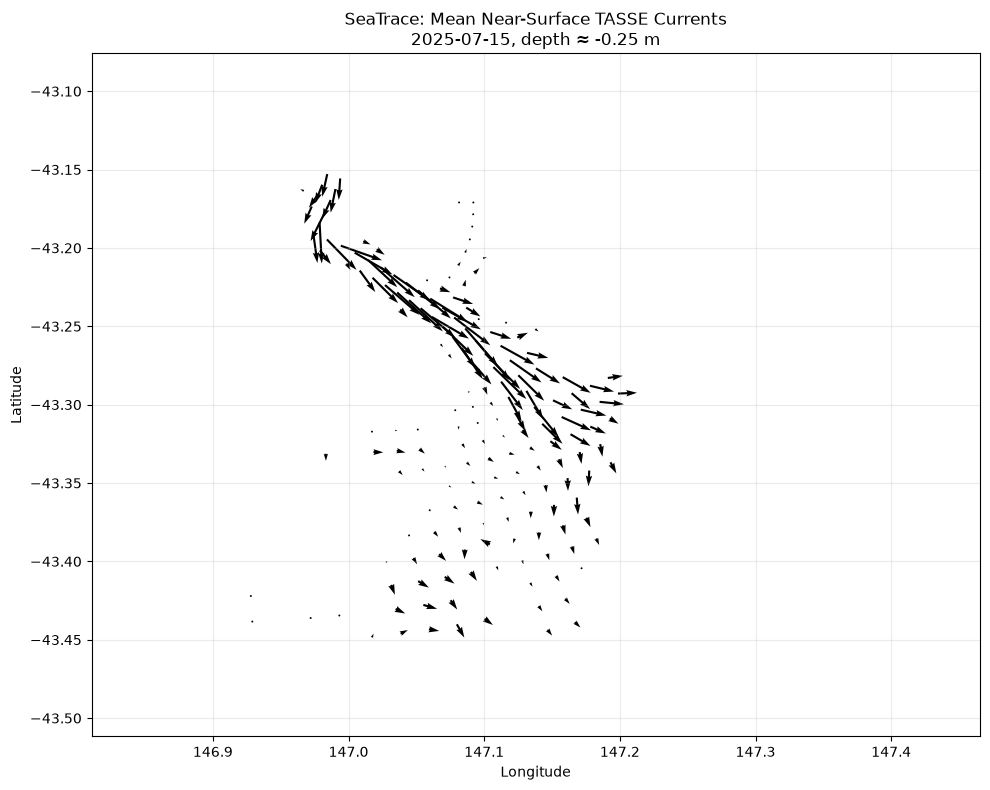

Saved plot: seatrace_tasse_output/tower_bay_mean_surface_currents_2025-07-15.png


In [13]:
mean_u = surface[U_VAR].mean(dim="time", skipna=True)
mean_v = surface[V_VAR].mean(dim="time", skipna=True)

lat2d = surface["latitude"].values
lon2d = surface["longitude"].values

# Reduce arrow density automatically to keep the plot readable.
max_arrows_per_axis = 30
stride_j = max(1, surface.sizes["j"] // max_arrows_per_axis)
stride_i = max(1, surface.sizes["i"] // max_arrows_per_axis)

plt.figure(figsize=(10, 8))

plt.quiver(
    lon2d[::stride_j, ::stride_i],
    lat2d[::stride_j, ::stride_i],
    mean_u.values[::stride_j, ::stride_i],
    mean_v.values[::stride_j, ::stride_i],
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    f"SeaTrace: Mean Near-Surface TASSE Currents\n"
    f"{SOURCE_DATE}, depth ≈ {actual_depth:.2f} m"
)
plt.grid(alpha=0.25)
plt.tight_layout()

plot_path = OUTPUT_DIR / f"tower_bay_mean_surface_currents_{SOURCE_DATE}.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved plot:", plot_path)

## 13. Export usable SeaTrace data

Three useful outputs are produced:

### A. NetCDF
Preserves the complete local gridded time series.  
**Best for:** Python/xarray, modelling and later particle tracking.

### B. Hourly CSV
One row per grid cell per hour.  
**Best for:** inspection, spreadsheets and GIS point import.

### C. Daily-mean CSV
One row per grid cell containing average daily surface current.  
**Best for:** quick GIS visualisation and current-arrow mapping.

In [14]:
# ---------------------------------------------------------------------
# A. COMPRESSED NETCDF
# ---------------------------------------------------------------------

nc_path = OUTPUT_DIR / f"tower_bay_surface_currents_{SOURCE_DATE}.nc"

encoding = {}
for name in [U_VAR, V_VAR, "current_speed", "current_direction_to_deg"]:
    encoding[name] = {
        "zlib": True,
        "complevel": 4,
        "dtype": "float32",
    }

surface.to_netcdf(
    nc_path,
    format="NETCDF4",
    encoding=encoding,
)

# ---------------------------------------------------------------------
# B. HOURLY CSV
# ---------------------------------------------------------------------

hourly_columns = [
    U_VAR,
    V_VAR,
    "current_speed",
    "current_direction_to_deg",
    "latitude",
    "longitude",
]

hourly_df = (
    surface[hourly_columns]
    .to_dataframe()
    .reset_index()
)

# Remove masked/land cells.
hourly_df = hourly_df.dropna(subset=[U_VAR, V_VAR])

hourly_csv_path = (
    OUTPUT_DIR / f"tower_bay_surface_currents_{SOURCE_DATE}.csv"
)

hourly_df.to_csv(hourly_csv_path, index=False)

# ---------------------------------------------------------------------
# C. DAILY-MEAN CSV
# ---------------------------------------------------------------------

daily_mean = surface[
    [U_VAR, V_VAR, "current_speed"]
].mean(dim="time", skipna=True)

# Direction must be recalculated from mean u and mean v.
daily_mean["current_direction_to_deg"] = (
    np.degrees(
        np.arctan2(daily_mean[U_VAR], daily_mean[V_VAR])
    ) + 360.0
) % 360.0

daily_mean = daily_mean.assign_coords(
    latitude=surface["latitude"],
    longitude=surface["longitude"],
)

mean_df = (
    daily_mean[
        [
            U_VAR,
            V_VAR,
            "current_speed",
            "current_direction_to_deg",
            "latitude",
            "longitude",
        ]
    ]
    .to_dataframe()
    .reset_index()
)

mean_df = mean_df.dropna(subset=[U_VAR, V_VAR])

mean_csv_path = (
    OUTPUT_DIR / f"tower_bay_mean_surface_currents_{SOURCE_DATE}.csv"
)

mean_df.to_csv(mean_csv_path, index=False)

print("Export complete.")

Export complete.


## 14. Preview the final usable data

In [15]:
print("Hourly current data:")
display(hourly_df.head(10))

print("\nDaily mean current data:")
display(mean_df.head(10))

print("\nHourly rows:", len(hourly_df))
print("Daily-mean grid cells:", len(mean_df))

Hourly current data:


,time,j,i,u,v,current_speed,current_direction_to_deg,latitude,longitude,zc
449,2025-07-14 14:00:00,2,89,0.007012,-0.014674,0.016264,154.458679,-43.449786,147.168360,-0.25
450,2025-07-14 14:00:00,2,90,0.003194,-0.009683,0.010197,161.744995,-43.448926,147.171761,-0.25
451,2025-07-14 14:00:00,2,91,0.002424,-0.006994,0.007402,160.886047,-43.448055,147.175155,-0.25
626,2025-07-14 14:00:00,3,86,0.012838,-0.024918,0.028030,152.741699,-43.449711,147.156945,-0.25
627,2025-07-14 14:00:00,3,87,0.014357,-0.025984,0.029687,151.078186,-43.448889,147.160352,-0.25
628,2025-07-14 14:00:00,3,88,0.013488,-0.026615,0.029838,153.125061,-43.448056,147.163752,-0.25
629,2025-07-14 14:00:00,3,89,0.006860,-0.013085,0.014775,152.332581,-43.447212,147.167145,-0.25
630,2025-07-14 14:00:00,3,90,0.008869,-0.021867,0.023597,157.923279,-43.446358,147.170530,-0.25
631,2025-07-14 14:00:00,3,91,0.006180,-0.017242,0.018316,160.281128,-43.445492,147.173908,-0.25
632,2025-07-14 14:00:00,3,92,0.001941,-0.006523,0.006806,163.430298,-43.444616,147.177279,-0.25



Daily mean current data:


,j,i,u,v,current_speed,current_direction_to_deg,latitude,longitude,zc
449,2,89,0.022958,-0.023046,0.038986,135.110229,-43.449786,147.168360,-0.25
450,2,90,0.014858,-0.011021,0.025263,126.566223,-43.448926,147.171761,-0.25
451,2,91,0.008544,-0.009749,0.015232,138.766479,-43.448055,147.175155,-0.25
626,3,86,0.031098,-0.037226,0.051863,140.124512,-43.449711,147.156945,-0.25
627,3,87,0.033118,-0.033839,0.052164,135.617584,-43.448889,147.160352,-0.25
628,3,88,0.031332,-0.032753,0.050741,136.271057,-43.448056,147.163752,-0.25
629,3,89,0.023725,-0.021616,0.037160,132.336823,-43.447212,147.167145,-0.25
630,3,90,0.023189,-0.028130,0.041760,140.499023,-43.446358,147.170530,-0.25
631,3,91,0.018402,-0.024076,0.034378,142.608337,-43.445492,147.173908,-0.25
632,3,92,0.007573,-0.010863,0.014662,145.117828,-43.444616,147.177279,-0.25



Hourly rows: 153360
Daily-mean grid cells: 6390


## 15. Final output files

In [16]:
print("SeaTrace current dataset generated successfully.\n")

print("1. NetCDF:")
print("  ", nc_path.resolve())

print("\n2. Hourly CSV:")
print("  ", hourly_csv_path.resolve())

print("\n3. Daily-mean CSV:")
print("  ", mean_csv_path.resolve())

print("\n4. Mean-current map:")
print("  ", plot_path.resolve())

print(
    "\nRecommended next step: use u/v from the NetCDF dataset "
    "to release virtual particles from the confirmed Tower Bay "
    "seaweed lease and simulate their movement through time."
)

SeaTrace current dataset generated successfully.

1. NetCDF:
   /home/n12506486/ifn680/IFN680_26s2/week_7/seatrace_tasse_output/tower_bay_surface_currents_2025-07-15.nc

2. Hourly CSV:
   /home/n12506486/ifn680/IFN680_26s2/week_7/seatrace_tasse_output/tower_bay_surface_currents_2025-07-15.csv

3. Daily-mean CSV:
   /home/n12506486/ifn680/IFN680_26s2/week_7/seatrace_tasse_output/tower_bay_mean_surface_currents_2025-07-15.csv

4. Mean-current map:
   /home/n12506486/ifn680/IFN680_26s2/week_7/seatrace_tasse_output/tower_bay_mean_surface_currents_2025-07-15.png

Recommended next step: use u/v from the NetCDF dataset to release virtual particles from the confirmed Tower Bay seaweed lease and simulate their movement through time.


# How these outputs fit SeaTrace

The resulting dataset does **not** claim to directly observe drifting seaweed.

Instead:

**Tower Bay seaweed farm / biomass**  
→ estimate shed material  
→ **TASSE `u` and `v` ocean currents**  
→ virtual particle transport  
→ decay / sinking / deposition assumptions  
→ GIS carbon-fate map

For the final project, replace the starter bounding box with the exact seaweed lease polygon or coordinates and use the relevant growing-season dates.

## 16. Interactive current map (Folium)

A static, pannable/zoomable web map of the **daily-mean** surface current at
each grid cell. Arrow length is a fixed visual length (not real distance
travelled); arrow colour and the tooltip both encode the actual current
speed and compass direction.

In [ ]:
%pip install -q folium branca

In [ ]:
import folium
import numpy as np
from branca.colormap import LinearColormap

# Remove invalid / land cells before mapping
map_df = mean_df.dropna(
    subset=["latitude", "longitude", "u", "v", "current_speed"]
).copy()

print("Valid grid cells for mapping:", len(map_df))
map_df.head()

In [ ]:
# Centre the map on the filtered study area
center_lat = map_df["latitude"].mean()
center_lon = map_df["longitude"].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="CartoDB positron")

# Speed colour scale
min_speed = map_df["current_speed"].min()
max_speed = map_df["current_speed"].max()

colormap = LinearColormap(
    colors=["blue", "cyan", "green", "yellow", "red"],
    vmin=min_speed, vmax=max_speed,
)
colormap.caption = "Ocean current speed (m/s)"
colormap.add_to(m)

# Reduce arrow density so the map stays readable
max_arrows = 300
step = max(1, len(map_df) // max_arrows)

# Visual-only arrow length: controls how long arrows LOOK on the map,
# NOT actual distance travelled by the water.
arrow_scale = 0.018

for _, row in map_df.iloc[::step].iterrows():
    lat, lon = row["latitude"], row["longitude"]
    u, v, speed = row["u"], row["v"], row["current_speed"]

    if speed <= 0:
        continue

    dlat = v * arrow_scale
    dlon = (u * arrow_scale) / np.cos(np.radians(lat))
    end_lat, end_lon = lat + dlat, lon + dlon

    arrow_color = colormap(speed)
    direction_deg = row["current_direction_to_deg"]  # compass bearing, 0=N, 90=E, ...

    # --- shaft ---
    folium.PolyLine(
        locations=[[lat, lon], [end_lat, end_lon]],
        color=arrow_color,
        weight=3,
        opacity=0.9,
        tooltip=f"Speed: {speed:.3f} m/s | Direction: {direction_deg:.1f}\u00b0",
    ).add_to(m)

    # --- arrowhead at the tip, rotated to match flow direction ---
    # "\u27a4" points East (compass 90\u00b0) by default, so rotate by (direction - 90)
    rotation = direction_deg - 90

    folium.Marker(
        location=[end_lat, end_lon],
        icon=folium.DivIcon(
            html=f'''
                <div style="
                    transform: rotate({rotation}deg);
                    transform-origin: center;
                    font-size: 18px;
                    font-weight: bold;
                    color: {arrow_color};
                    line-height: 18px;
                ">\u27a4</div>
            '''
        ),
    ).add_to(m)

interactive_map_path = OUTPUT_DIR / f"tower_bay_interactive_currents_{SOURCE_DATE}.html"
m.save(interactive_map_path)
print("Saved interactive map:", interactive_map_path.resolve())

m

## 17. Animated surface-current flow

The static arrow map above is a single daily-mean snapshot. This section
instead builds a **looping flow animation** in the style of ocean-current
visualisations such as NASA's *Perpetual Ocean* or the
[PBS current/energy-redistribution animation](https://www.pbslearningmedia.org/resource/buac17-912-sci-ess-currents/ocean-currents-and-energy-redistribution-around-earth/):
short glowing "comet" streaks continuously flow across the map, coloured
and paced by the local current speed, so direction and relative strength
are both visible at a glance.

How it works:

1. A few hundred particles are seeded across the valid (non-land) grid cells.
2. For **every real hour in this TASSE file**, each particle's local `u`/`v`
   vector is looked up (nearest-neighbour) from the actual model data — so
   the animation reflects genuine hour-to-hour changes in the current field,
   not a fabricated pattern.
3. Each particle is drawn as a short streak that slides along its local
   flow direction on a repeating cycle; faster currents cycle (visually
   "flow") faster. **Streak length is a fixed visual length, not real
   distance travelled** — real TASSE speeds here are too small to see
   meaningful physical displacement over a single day at this map scale.
4. The background shading shows the daily-mean current speed for context.

The result is saved as a GIF so it can be viewed outside Jupyter too.

In [ ]:
%pip install -q scipy pillow

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.collections import LineCollection
from scipy.interpolate import NearestNDInterpolator
from IPython.display import Image as IPImage

rng = np.random.default_rng(42)

# ==========================================================
# 1. Build a per-hour nearest-neighbour lookup of u/v
# ==========================================================
n_times = surface.sizes["time"]
lat_flat = np.ma.filled(np.asarray(surface["latitude"].values, dtype=float), np.nan).ravel()
lon_flat = np.ma.filled(np.asarray(surface["longitude"].values, dtype=float), np.nan).ravel()

# Cells that are valid (non-land, with finite coordinates) at hour 0 are
# valid for the whole day. Some curvilinear grid points can carry fill
# values (masked / NaN) in the lat-lon arrays themselves, not just in u/v.
valid_mask_flat = (
    np.isfinite(surface[U_VAR].isel(time=0).values.ravel())
    & np.isfinite(lat_flat)
    & np.isfinite(lon_flat)
)
pts = np.column_stack([lon_flat[valid_mask_flat], lat_flat[valid_mask_flat]])

u_interps, v_interps = [], []
for t in range(n_times):
    u_t = surface[U_VAR].isel(time=t).values.ravel()[valid_mask_flat]
    v_t = surface[V_VAR].isel(time=t).values.ravel()[valid_mask_flat]
    u_interps.append(NearestNDInterpolator(pts, u_t))
    v_interps.append(NearestNDInterpolator(pts, v_t))

max_speed_overall = float(surface["current_speed"].max(skipna=True).values)

# ==========================================================
# 2. Seed particles across the valid domain
# ==========================================================
n_particles = 350
seed_idx = rng.choice(len(pts), size=n_particles, replace=True)
seed_lon = pts[seed_idx, 0].copy()
seed_lat = pts[seed_idx, 1].copy()

# Random phase per particle so streaks don't all pulse in lock-step
phase_offset = rng.uniform(0, 1, size=n_particles)

# Visual-only streak length (degrees) and how much of it is drawn as a tail
L = 0.02
tail_frac = 0.25
frames_per_hour = 6  # animation smoothness between real hourly fields

# ==========================================================
# 3. Static background: daily-mean current speed
# ==========================================================
mean_speed = surface["current_speed"].mean(dim="time", skipna=True).values

def fill_nearest_2d(arr):
    """Fill NaN cells in a 2-D array with their nearest finite neighbour.

    pcolormesh refuses non-finite X/Y coordinates, and filling gaps with
    a single global value (e.g. the mean) badly distorts the inferred
    cell edges of neighbouring *valid* cells. A nearest-neighbour fill
    keeps filled coordinates spatially consistent with their
    surroundings, so the mesh stays undistorted. The affected cells
    still render as blank because mean_speed (C) is NaN there.
    """
    from scipy.ndimage import distance_transform_edt

    arr = np.asarray(arr, dtype=float)
    invalid = ~np.isfinite(arr)
    if not invalid.any():
        return arr
    _, idx = distance_transform_edt(invalid, return_distances=True, return_indices=True)
    return arr[tuple(idx)]

plot_lon = fill_nearest_2d(np.ma.filled(np.asarray(surface["longitude"].values, dtype=float), np.nan))
plot_lat = fill_nearest_2d(np.ma.filled(np.asarray(surface["latitude"].values, dtype=float), np.nan))

fig, ax = plt.subplots(figsize=(9, 8))
mesh = ax.pcolormesh(
    plot_lon, plot_lat, mean_speed,
    cmap="Blues", shading="auto", alpha=0.55,
)
plt.colorbar(mesh, ax=ax, shrink=0.85, label="Mean current speed (m/s)")

norm = plt.Normalize(vmin=0, vmax=max_speed_overall)
cmap = plt.cm.autumn_r

streaks = LineCollection([], linewidths=2, cmap=cmap, norm=norm)
ax.add_collection(streaks)
heads = ax.scatter([], [], s=12, c=[], cmap=cmap, norm=norm, edgecolors="k", linewidths=0.3)

ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
title = ax.set_title("")

# ==========================================================
# 4. Animate: advance each particle along its local flow vector
# ==========================================================
def update(frame):
    t = (frame // frames_per_hour) % n_times

    u_t = u_interps[t](seed_lon, seed_lat)
    v_t = v_interps[t](seed_lon, seed_lat)
    spd_t = np.hypot(u_t, v_t)

    # Unit direction, corrected for longitude convergence at this latitude
    dx = u_t / np.cos(np.radians(seed_lat))
    dy = v_t
    mag = np.hypot(dx, dy)
    mag[mag == 0] = 1e-9
    dx_unit, dy_unit = dx / mag, dy / mag

    # Faster currents cycle through their streak path faster
    speed_norm = np.clip(spd_t / max(max_speed_overall, 1e-9), 0.15, 1.0)
    frac = (frame * speed_norm / frames_per_hour + phase_offset) % 1.0
    tail_start = np.clip(frac - tail_frac, 0, 1)

    lon_head = seed_lon + dx_unit * L * frac
    lat_head = seed_lat + dy_unit * L * frac
    lon_tail = seed_lon + dx_unit * L * tail_start
    lat_tail = seed_lat + dy_unit * L * tail_start

    segments = np.stack(
        [np.column_stack([lon_tail, lat_tail]), np.column_stack([lon_head, lat_head])],
        axis=1,
    )
    streaks.set_segments(segments)
    streaks.set_array(spd_t)

    heads.set_offsets(np.column_stack([lon_head, lat_head]))
    heads.set_array(spd_t)

    hour = surface["time"].values[t]
    title.set_text(
        f"SeaTrace: Animated Surface Current Flow\n"
        f"{SOURCE_DATE} \u2014 {np.datetime_as_string(hour, unit='h')}"
    )
    return streaks, heads, title

n_frames = n_times * frames_per_hour
anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=120, blit=False)

flow_gif_path = OUTPUT_DIR / f"tower_bay_current_flow_{SOURCE_DATE}.gif"
anim.save(flow_gif_path, writer="pillow", fps=10)
plt.close(fig)

print("Saved animated flow map:", flow_gif_path.resolve())
IPImage(filename=str(flow_gif_path))